# **Prediksi Kelangsungan Hidup Karakter Game of Thrones Denga Random Forest**

# **1. Business Understanding**


## **1.1 Latar Belakang**

Sebuah tim analis media dan penerbitan buku novel inign membangun machine learning untuk meprediksi tingkat kelangs hidup dari novel Game of Thrones.

## **1.2 Tujuan**

Membangun machine learning menggunakan Random Forest untuk memprediksi tingkat kelangsungan hidup karakter.

## **1.3 Masalah**

Dalam menganalisis data, tim analis masih menggunakan cara manual sehingga memperlukan waktu yang lama dan tidak efesien.

## **1.4 Solusi**

Membangun machine learning dengan menggunakan Random Forest untuk memprediksi tingkat kelangsungan hidup karakter.

## **1.5 Deskripsi Tabbel**

`Fitur Input (X): 29 kolom atribut latar belakang karakter dan keterlibatan cerita, yang meliputi : `
- S.No: Nomor urut identifikasi data (fitur indeks/ID).
- plod: Nilai estimasi probabilitas kematian berdasarkan analisis statistik (Probability of Life or Death).
- name: Nama lengkap karakter.
- title: Gelar/jabatan karakter (misal: Lord, Ser, Queen).
- gender: Jenis kelamin karakter (Kategori biner: 1 untuk Pria, 0 untuk Wanita).
- culture: Latar belakang kebudayaan/suku asal karakter (misal: Rivermen,
Dornish, Northmen).
- dateOfBirth: Tahun kelahiran karakter (satuan: Tahun/Era Westeros).
- DateoFdeath: Tahun kematian karakter (jika sudah meninggal).
- mother: Nama ibu dari karakter.
- father: Nama ayah dari karakter.
- heir: Nama ahli waris dari karakter.
- house: Nama klan/keluarga (House) utama (misal: House Stark, House
Lannister, House Targaryen).
- spouse: Nama pasangan/suami/istri dari karakter.
-  book1: Indikator kemunculan karakter pada Buku 1 (A Game of Thrones)
(Kategori biner: 1 muncul, 0 tidak).
- book2: Indikator kemunculan karakter pada Buku 2 (A Clash of Kings)
(Kategori biner: 1 muncul, 0 tidak).
- book3: Indikator kemunculan karakter pada Buku 3 (A Storm of Swords)
(Kategori biner: 1 muncul, 0 tidak).
- book4: Indikat    or kemunculan karakter pada Buku 4 (A Feast for Crows)
(Kategori biner: 1 muncul, 0 tidak).
-  book5: Indikator kemunculan karakter pada Buku 5 (A Dance with Dragons)
(Kategori biner: 1 muncul, 0 tidak).
-  isAliveMother: Status kelangsungan hidup ibu karakter (Kategori biner: 1
hidup, 0 meninggal).
-  isAliveFather: Status kelangsungan hidup ayah karakter (Kategori biner: 1
hidup, 0 meninggal).
-  isAliveHeir: Status kelangsungan hidup ahli waris (Kategori biner: 1 hidup, 0
meninggal).
-  isAliveSpouse: Status kelangsungan hidup pasangan (Kategori biner: 1
hidup, 0 meninggal).
-  isMarried: Status pernikahan karakter (Kategori biner: 1 menikah, 0 tidak).
-  isNoble: Status kebangsawaan karakter (Kategori biner: 1 bangsawan, 0
rakyat biasa).
-  age: Usia karakter (satuan: Tahun)
-  numDeadRelations: Jumlah kerabat/keluarga dekat karakter yang telah
meninggal (satuan: Orang).
-  boolDeadRelations: Indikator apakah karakter memiliki kerabat yang
meninggal (Kategori biner: 1 ya, 0 tidak).
-  isPopular: Indikator apakah karakter merupakan tokoh populer (Kategori
biner: 1 ya, 0 tidak).
-  popularity: Skor tingkat popularitas karakter dalam cerita (satuan: Skala rasio
0.0 sampai 1.0).

` Target Label (Y): ` 
Kolom isAlive di bagian akhir yang berisi angka biner (0 = Karakter Meninggal, 1 = Karakter Masih Hidup).

# **2. Data Preparation**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tkinter as tk
from tkinter import ttk, messagebox
from collections import Counter
import random

In [2]:
df = pd.read_csv('../dataset/HW2.csv')
# df = pd.read_csv('HW2.csv')
df.head(10)

,S.No,plod,name,title,gender,culture,dateOfBirth,DateoFdeath,mother,father,...,isAliveHeir,isAliveSpouse,isMarried,isNoble,age,numDeadRelations,boolDeadRelations,isPopular,popularity,isAlive
0,1,0.946,Viserys II Targaryen,NaN,1,NaN,NaN,NaN,Rhaenyra Targaryen,Daemon Targaryen,...,0.0,NaN,0,0,NaN,11,1,1,0.605351,0
1,2,0.613,Walder Frey,Lord of the Crossing,1,Rivermen,208.0,NaN,NaN,NaN,...,NaN,1.0,1,1,97.0,1,1,1,0.896321,1
2,3,0.507,Addison Hill,Ser,1,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0,1,NaN,0,0,0,0.267559,1
3,4,0.924,Aemma Arryn,Queen,0,NaN,82.0,105.0,NaN,NaN,...,NaN,0.0,1,1,23.0,0,0,0,0.183946,0
4,5,0.383,Sylva Santagar,Greenstone,0,Dornish,276.0,NaN,NaN,NaN,...,NaN,1.0,1,1,29.0,0,0,0,0.043478,1
5,6,0.979,Tommen Baratheon,NaN,1,NaN,NaN,NaN,Cersei Lannister,Robert Baratheon,...,1.0,NaN,0,0,NaN,5,1,1,1.000000,1
6,7,0.986,Valarr Targaryen,Hand of the King,1,Valyrian,183.0,209.0,NaN,NaN,...,NaN,1.0,1,1,26.0,0,0,1,0.431438,0
7,8,0.964,Viserys I Targaryen,NaN,1,NaN,NaN,NaN,Alyssa Targaryen,Baelon Targaryen,...,1.0,NaN,0,0,NaN,5,1,1,0.678930,0
8,9,0.276,Wilbert,Ser,1,NaN,NaN,298.0,NaN,NaN,...,NaN,NaN,0,1,NaN,0,0,0,0.006689,0
9,10,0.609,Wilbert Osgrey,Ser,1,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0,1,NaN,0,0,0,0.020067,1


In [3]:
df.info()
df.describe()
print('========================================================')
df.size


<class 'pandas.DataFrame'>
RangeIndex: 1946 entries, 0 to 1945
Data columns (total 30 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   S.No               1946 non-null   int64  
 1   plod               1946 non-null   float64
 2   name               1946 non-null   str    
 3   title              938 non-null    str    
 4   gender             1946 non-null   int64  
 5   culture            677 non-null    str    
 6   dateOfBirth        433 non-null    float64
 7   DateoFdeath        444 non-null    float64
 8   mother             21 non-null     str    
 9   father             26 non-null     str    
 10  heir               23 non-null     str    
 11  house              1519 non-null   str    
 12  spouse             276 non-null    str    
 13  book1              1946 non-null   int64  
 14  book2              1946 non-null   int64  
 15  book3              1946 non-null   int64  
 16  book4              1946 non-null   

58380

In [4]:
null = pd.DataFrame({'Missing Value': df.isnull().sum(), 'Persentase': df.isnull().sum() / len(df) * 100})
null.sort_values(by='Missing Value', ascending=False)


,Missing Value,Persentase
mother,1925,98.920863
isAliveMother,1925,98.920863
isAliveHeir,1923,98.818088
heir,1923,98.818088
father,1920,98.663926
isAliveFather,1920,98.663926
isAliveSpouse,1670,85.817061
spouse,1670,85.817061
dateOfBirth,1513,77.749229
age,1513,77.749229


In [5]:
df.duplicated().sum()

np.int64(0)

# **3. EDA**

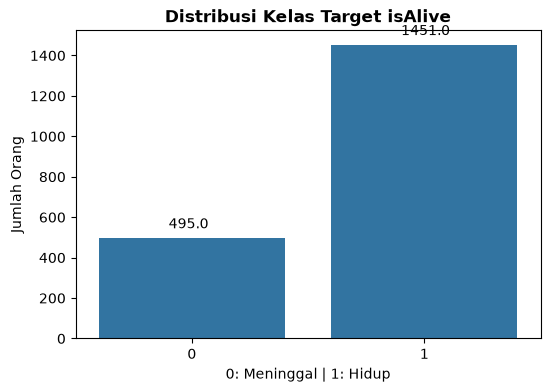

In [6]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='isAlive', data=df)
plt.title('Distribusi Kelas Target isAlive', fontsize=12, fontweight='bold')
plt.xlabel('0: Meninggal | 1: Hidup')
plt.ylabel('Jumlah Orang')

for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + 0.3, p.get_height() + 50))
plt.show()

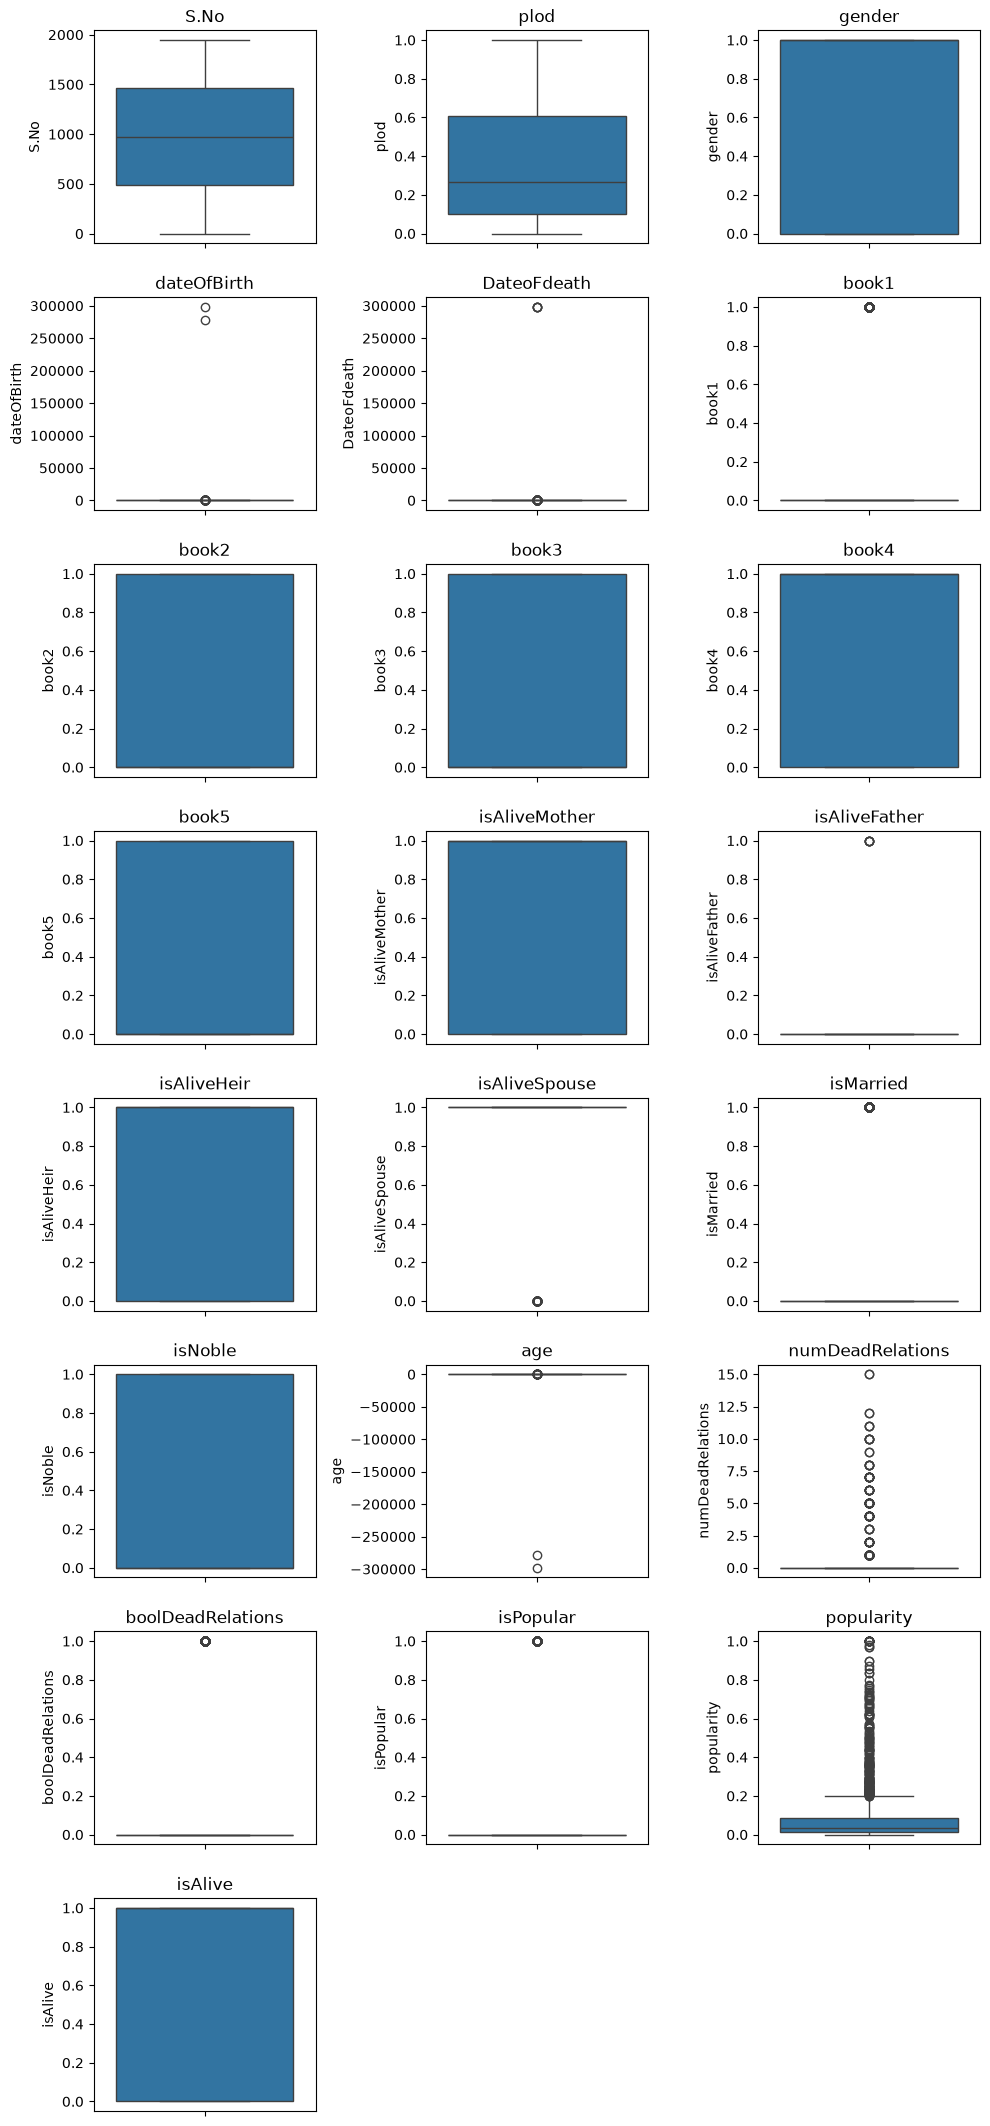

In [7]:
cols = df.select_dtypes(include=['number']).columns

plt.figure(figsize=(10, 40))

for i, column in enumerate(cols, start=1):
    plt.subplot(15, 3, i)
    sns.boxplot(df[column])
    plt.title(column)

plt.tight_layout(h_pad=2)
plt.show()

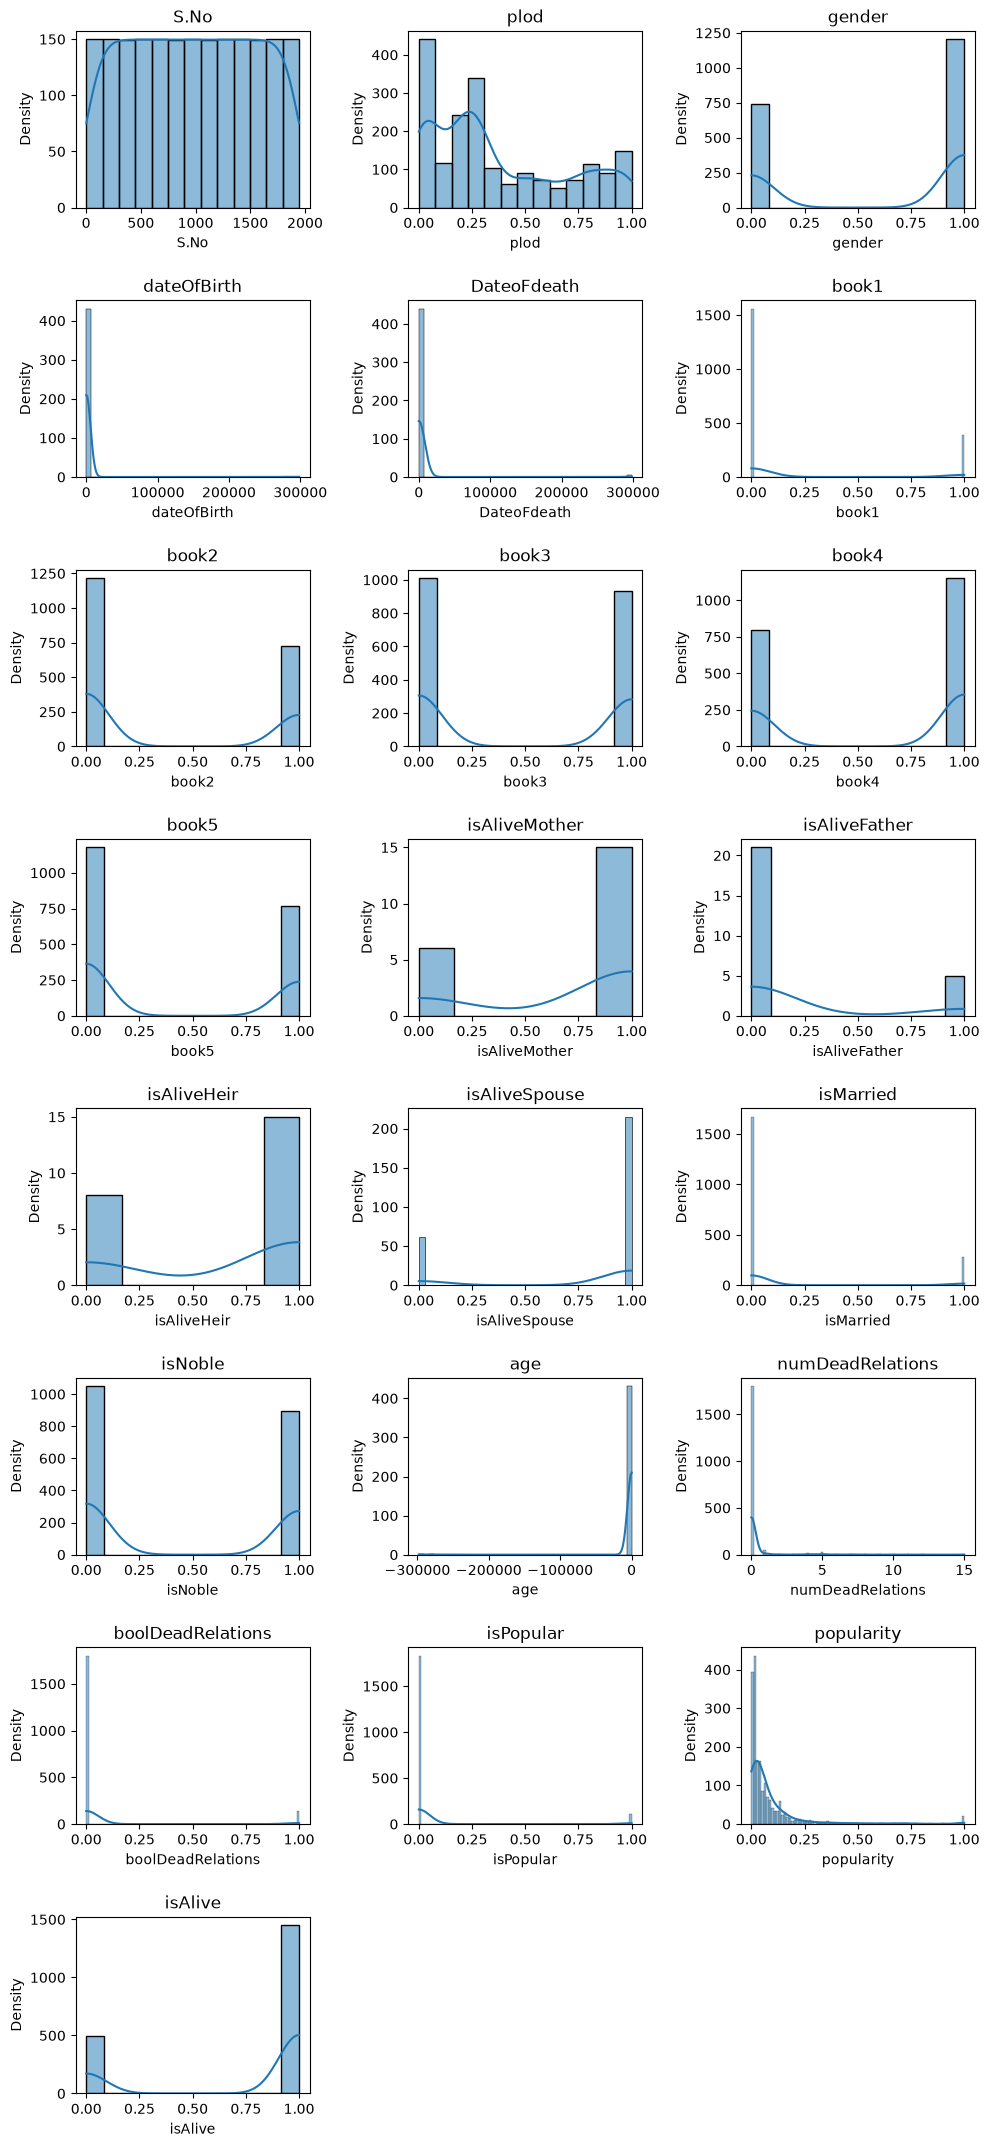

In [8]:
cols = df.select_dtypes(include=['number']).columns

plt.figure(figsize=(10, 40))

for i, column in enumerate(cols, start=1):
    plt.subplot(15, 3, i)
    sns.histplot(df[column], kde=True)
    plt.xlabel(column)
    plt.ylabel('Density')
    plt.title(column)

plt.tight_layout(h_pad=2)
plt.show()

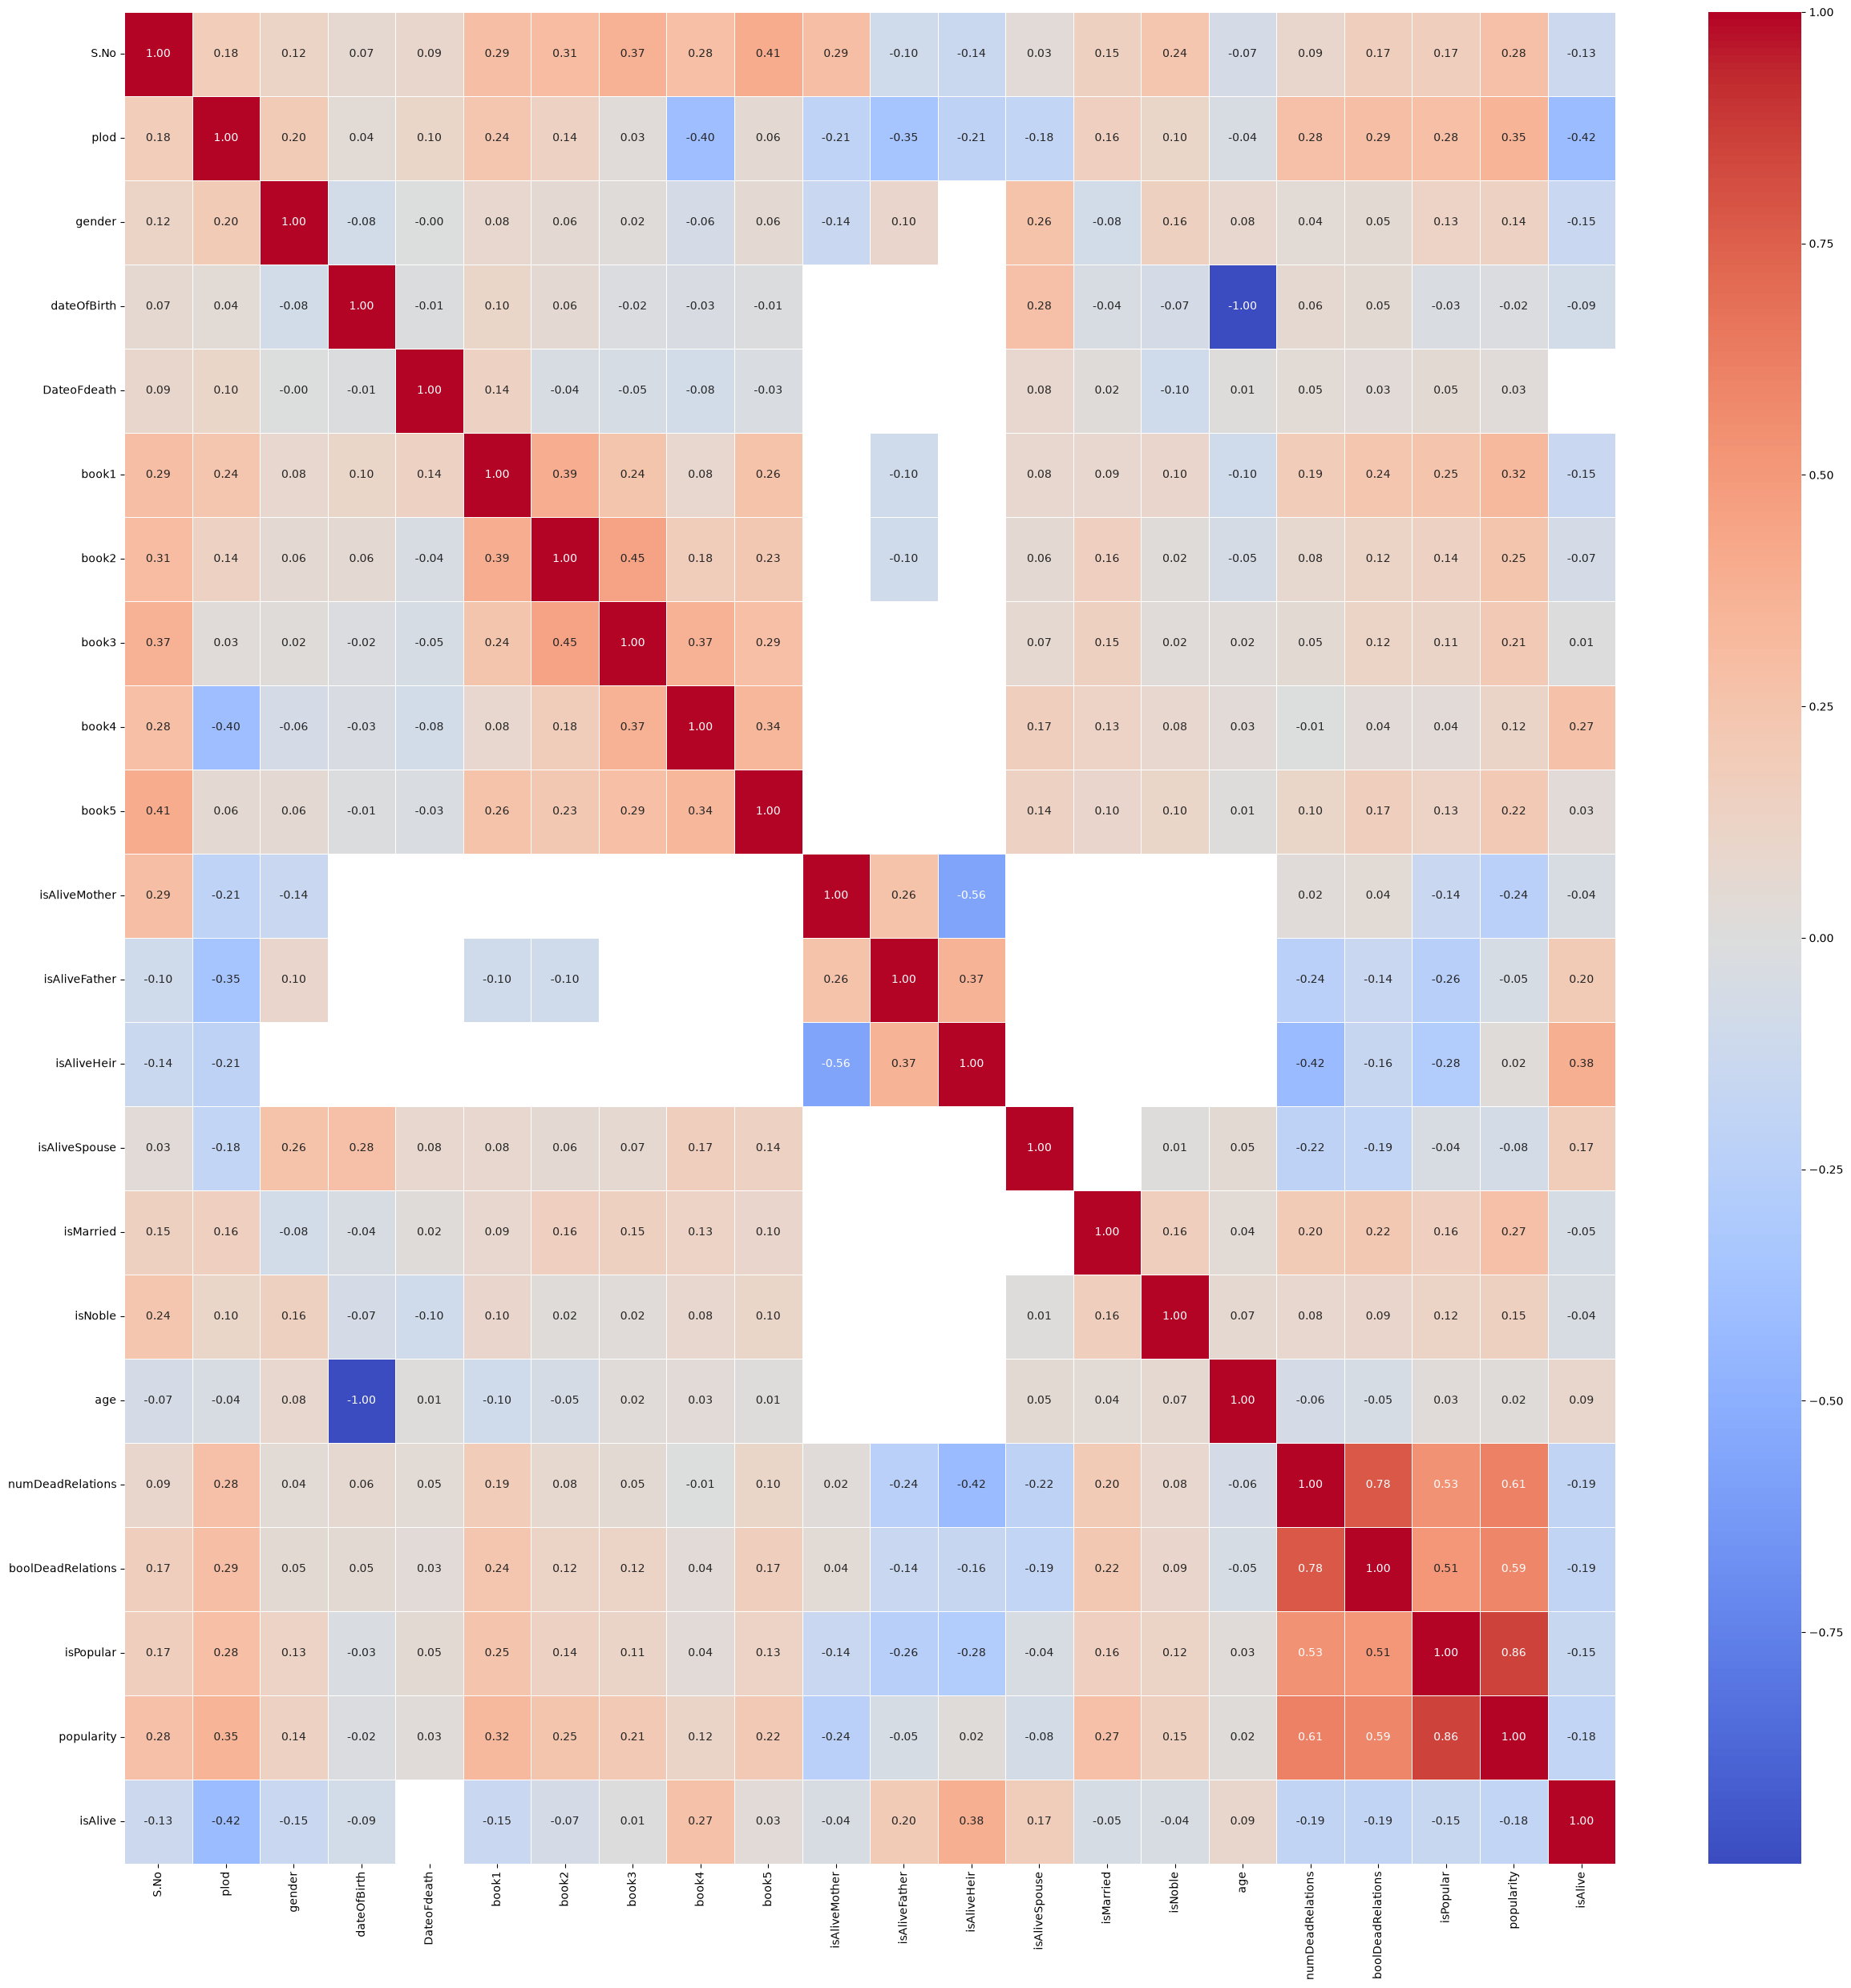

In [9]:
df_corr = df.select_dtypes(include=['int64', 'float64']).corr()
plt.figure(figsize=(30,30))

sns.heatmap(df_corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.show()

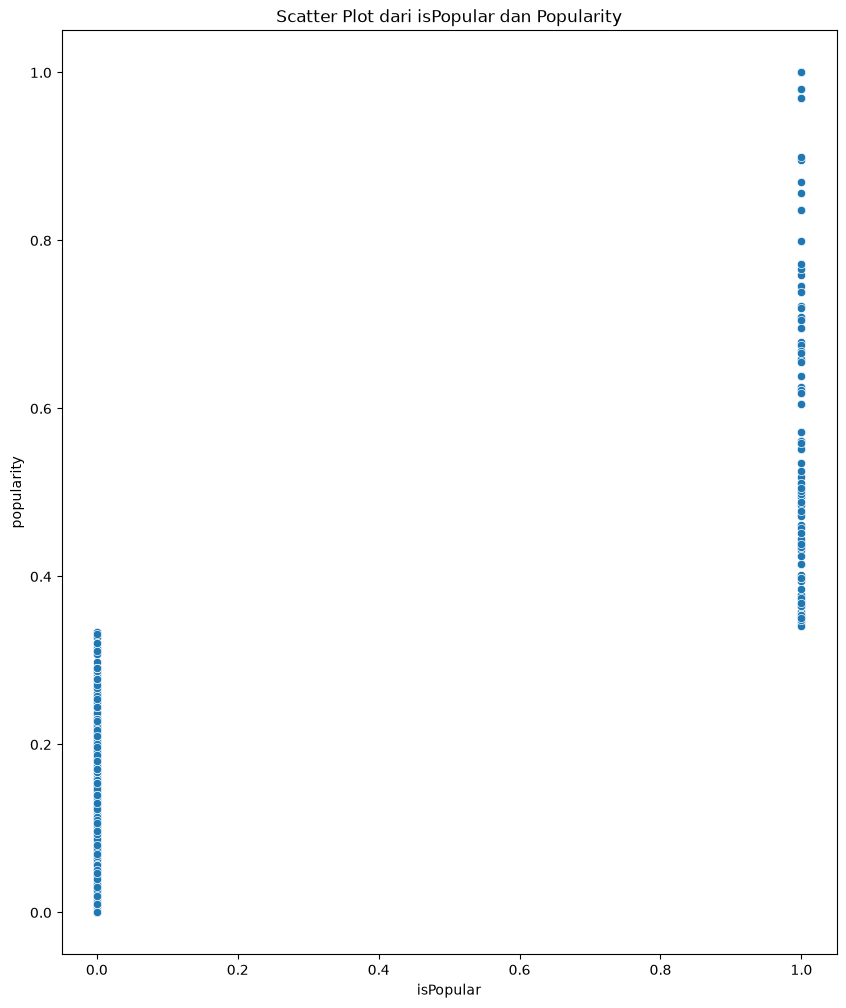

In [10]:
plt.figure(figsize=(10, 12))

sns.scatterplot(x='isPopular', y='popularity', data=df)
plt.title('Scatter Plot dari isPopular dan Popularity')
plt.show()

# **4. Data Pre Processing**

In [11]:
df = df.drop(columns=['name', 'S.No', 'dateOfBirth', 'DateoFdeath'])

In [12]:
# 1. Ubah teks nama menjadi: 1 (Kalau punya) dan 0 (Kalau tidak punya)
df['has_mother'] = df['mother'].notnull().astype(int)
df['has_father'] = df['father'].notnull().astype(int)
df['has_heir']   = df['heir'].notnull().astype(int)
df['has_spouse'] = df['spouse'].notnull().astype(int)

# 2. Status hidup keluarganya:
# 1 = Hidup, 0 = Mati, -1 = Tidak tercatat / Tidak punya
for col in ['isAliveMother', 'isAliveFather', 'isAliveHeir', 'isAliveSpouse']:
    df[col] = df[col].fillna(-1)

df = df.drop(columns=['mother', 'father', 'heir', 'spouse'])

Feature Engineering karena untuk mengoptimalkan performa model dan menghindari overfitting. Selain itu juga untuk menghindari kesalah pahaman model.

In [13]:
df.loc[df['age'] < 0, 'age'] = np.nan

Disini kenapa umur di nan karena di dataset terdapat nilai negatif jadi diganti dengan nilai nan untuk sementara.

In [14]:
df.head(15)

,plod,title,gender,culture,house,book1,book2,book3,book4,book5,...,age,numDeadRelations,boolDeadRelations,isPopular,popularity,isAlive,has_mother,has_father,has_heir,has_spouse
0,0.946,NaN,1,NaN,NaN,0,0,0,0,0,...,NaN,11,1,1,0.605351,0,1,1,1,0
1,0.613,Lord of the Crossing,1,Rivermen,House Frey,1,1,1,1,1,...,97.0,1,1,1,0.896321,1,0,0,0,1
2,0.507,Ser,1,NaN,House Swyft,0,0,0,1,0,...,NaN,0,0,0,0.267559,1,0,0,0,0
3,0.924,Queen,0,NaN,House Arryn,0,0,0,0,0,...,23.0,0,0,0,0.183946,0,0,0,0,1
4,0.383,Greenstone,0,Dornish,House Santagar,0,0,0,1,0,...,29.0,0,0,0,0.043478,1,0,0,0,1
5,0.979,NaN,1,NaN,NaN,0,0,0,0,0,...,NaN,5,1,1,1.000000,1,1,1,1,0
6,0.986,Hand of the King,1,Valyrian,House Targaryen,0,0,0,0,0,...,26.0,0,0,1,0.431438,0,0,0,0,1
7,0.964,NaN,1,NaN,NaN,0,0,0,0,0,...,NaN,5,1,1,0.678930,0,1,1,1,0
8,0.276,Ser,1,NaN,NaN,0,0,1,0,0,...,NaN,0,0,0,0.006689,0,0,0,0,0
9,0.609,Ser,1,NaN,House Osgrey,0,0,0,0,0,...,NaN,0,0,0,0.020067,1,0,0,0,0


In [15]:
X = df.drop(columns='isAlive')
y = df['isAlive']

In [16]:
def split_data(X, y, train_size=0.8, random_state=42):
    np.random.seed(random_state)
    idx = np.random.permutation(len(X))
    split_ratio = int(train_size * len(X))
    X_train, X_test = X.iloc[idx[:split_ratio]], X.iloc[idx[split_ratio:]]
    y_train, y_test = y.iloc[idx[:split_ratio]], y.iloc[idx[split_ratio:]]
    return X_train, X_test, y_train, y_test

X_train, X_test, y_train, y_test = split_data(X, y)

Alasan data di split di awal karena untuk menhindari kebocoran data latih ke data uji.

In [17]:
# kolom_teks = X_train.select_dtypes(include=['object', 'category', 'string']).columns
# for col in kolom_teks:
#     X_train[col] = X_train[col].fillna(X_train[col].mode()[0])

# kolom_num = X_train.select_dtypes(include=['number']).columns
# for col in kolom_num:
#     X_train[col] = X_train[col].fillna(X_train[col].median())

# # TEST
# kolom_teks = X_test.select_dtypes(include=['object', 'category', 'string']).columns
# for col in kolom_teks:
#     X_test[col] = X_test[col].fillna(X_train[col].mode()[0])

# kolom_num = X_test.select_dtypes(include=['number']).columns
# for col in kolom_num:
#     X_test[col] = X_test[col].fillna(X_test[col].median())



In [18]:

# 1. Mengambil kolom numerik
num_cols = X_train.select_dtypes(include=['number']).columns

# 2. Mengisi missing value numerik menggunakan median
for col in num_cols:
    med = X_train[col].median()

    X_train[col] = X_train[col].fillna(med)
    X_test[col] = X_test[col].fillna(med)


# 3. Mengambil kolom kategorikal
cat_cols = X_train.select_dtypes(include=['object', 'str']).columns

# 4. Mengubah data kategorikal menjadi angka
for col in cat_cols:
    X_train[col], uniques = pd.factorize(
        X_train[col].fillna('Unknown')
    )

    X_test[col] = uniques.get_indexer(
        X_test[col].fillna('Unknown')
    )


Kemduan handling missing value pada number digunakan media untuk menjaga keaslian data dan pada teks itu menggunakan unknown karena supaya data tidak salah memrpediksi contoh seperti gelar agar yang aslinya gelarnya bawah maka nanti akan di prediksi gelar atas


In [19]:
cols = X_train.select_dtypes(include=['number']).columns

Q1 = X_train[cols].quantile(0.25)
Q3 = X_train[cols].quantile(0.75)

IQR = Q3 - Q1 

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outlier = ((X_train[cols] < batas_bawah) | (X_train[cols] > batas_atas)).sum()

hasil = pd.DataFrame({'Outlier': outlier, 'Persentase': outlier / len(X_train) * 100})
hasil.sort_values(by='Outlier', ascending=False)


,Outlier,Persentase
age,341,21.915167
book1,305,19.601542
title,276,17.737789
isAliveSpouse,234,15.038560
isMarried,234,15.038560
has_spouse,234,15.038560
culture,192,12.339332
popularity,165,10.604113
boolDeadRelations,121,7.776350
numDeadRelations,121,7.776350


Disini outlier tidak di handling karena outlier tidak berpengaruh pada hasil prediksi.

In [20]:
# 5. Mengubah DataFrame menjadi NumPy array
X_train = X_train.values
X_test = X_test.values

y_train = y_train.values
y_test = y_test.values

print(X_train)
print(y_train)
print(X_test)
print(y_test)


[[ 0.273  0.     1.    ...  0.     0.     0.   ]
 [ 0.261  1.     1.    ...  0.     0.     0.   ]
 [ 0.685  0.     1.    ...  0.     0.     0.   ]
 ...
 [ 0.341  0.     1.    ...  0.     0.     0.   ]
 [ 0.959  3.     1.    ...  0.     0.     0.   ]
 [ 0.075 52.     1.    ...  0.     0.     1.   ]]
[0 1 0 ... 1 0 1]
[[  0.633 158.      1.    ...   0.      0.      0.   ]
 [  0.535  -1.      1.    ...   0.      0.      0.   ]
 [  0.947  56.      1.    ...   0.      0.      0.   ]
 ...
 [  0.468   0.      1.    ...   0.      0.      0.   ]
 [  0.338   3.      1.    ...   0.      0.      1.   ]
 [  0.275   3.      1.    ...   0.      0.      0.   ]]
[0 1 1 1 0 1 0 1 0 1 1 1 1 1 1 1 0 1 0 1 1 1 1 1 1 0 1 1 0 1 0 1 0 1 0 1 1
 1 1 1 1 1 1 1 0 1 0 1 1 0 1 0 1 1 1 1 1 1 0 0 0 1 1 1 0 1 1 1 1 1 1 0 1 0
 1 1 1 1 1 0 1 1 1 1 1 1 0 1 0 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 0 1 0 1 0 1 1
 1 1 1 1 1 0 1 1 0 0 0 1 0 1 1 1 0 1 1 1 1 1 1 1 0 1 1 1 0 0 0 0 1 1 1 1 0
 1 1 1 1 1 1 0 1 0 1 1 0 1 1 1 1 1 1 1 0 1 0 1

Di encoding untuk array karena suapaya dapat dihitung dengan numpy

# **5. Modelling**

#### Membuat class decision tree

In [21]:
class DecisionTree:
    def __init__(self, max_depth=4, min_samples_split=2, max_features="sqrt"):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.max_features = max_features
        self.tree = None

    def fit(self, X, y):
        self.tree = self._build_tree(X, y , depth=0)

    def _entropy(self,y):    #Entropy utk menilai kemurnian hasil pemisahan
        counts = Counter(y).values()
        return -sum((c / len(y)) * np.log2(c / len(y)) for c in counts if c > 0)

    def _build_tree(self, X, y, depth):
        if depth >= self.max_depth or len(y) < self.min_samples_split or len(np.unique(y)) == 1:
            return Counter(y).most_common(1)[0][0] # melakukan voting jika sudah mencapai depth maksimal

        n_feats = X.shape[1]
        k = max(1, int(np.sqrt(n_feats))) if self.max_features == "sqrt" else n_feats #mengambil akar dari panjang fitur
        feat_indices = np.random.choice(n_feats, size=k, replace=False)

        best_gain, best_feat, best_val = -1,None,None
        parent_ent = self._entropy(y) #hiutng secampur apa sebelum di belah


        for f in feat_indices:  # mencari information gain untuk menentukan fitur dan threshold yang di pake
            for val in np.unique(X[:,f]):
                left_mask = X[:, f] <= val
                if sum(left_mask) == 0 or sum(left_mask) == len(y):
                    continue

                left_ent = self._entropy(y[left_mask])
                right_ent = self._entropy(y[~left_mask])
                gain = parent_ent - (sum(left_mask)/len(y) * left_ent + sum(~left_mask)/len(y) * right_ent)

                if gain > best_gain:
                    best_gain, best_feat, best_val = gain, f, val

        if best_gain <=0 :
            return Counter(y).most_common(1)[0][0]

        left_mask = X[:, best_feat] <= best_val
        return {
            'feat' : best_feat,
            'val' : best_val,
            'gain' : best_gain,
            'n_samples' : len(y),
            'left': self._build_tree(X[left_mask],y[left_mask], depth + 1),
            'right': self._build_tree(X[~left_mask],y[~left_mask], depth + 1)
        }

    def predict(self, X):
        return np.array([self._predict(x,self.tree) for x in X])

    def _predict(self, x, node):
        if not isinstance(node,dict):
            return node
        if x[node['feat']] <= node['val']:
            return self._predict(x , node['left'])
        return self._predict(x,node['right'])

#### Membuat class random forest

In [22]:
class RandomForest:
    def __init__(self,n_trees=1, max_depth=1, min_samples_split=2, max_features='sqrt'):
        self.n_trees = n_trees
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.max_features = max_features
        self.trees = []

    def fit(self, X, y):
        self.trees = []
        n_samples = len(X)
        self.n_features = X.shape[1]
        

        for _ in range(self.n_trees): # menentukan bootstrap sample atau bagging
            idx = np.random.choice(n_samples, size = n_samples, replace=True)

            tree = DecisionTree(
                max_depth = self.max_depth,
                min_samples_split = self.min_samples_split,
                max_features = self.max_features
            )
            tree.fit(X[idx], y[idx])
            self.trees.append(tree)

    def predict(self, X): #kumpul vot hasil pohon
        tree_preds = np.array([tree.predict(X) for tree in self.trees])

        return np.array([Counter(tree_preds[:, i]).most_common(1)[0][0] for i in range(len(X))])

    def feature_importances(self): # menghitung sengaruh apa tiap fitur pada di semua cabang masing2 phon
        importances = np.zeros(self.n_features)

        def collect_gains(node):
            if isinstance(node, dict):
                importances[node['feat']] += node['gain'] * node['n_samples']
                collect_gains(node['left'])
                collect_gains(node['right'])

        for tree in self.trees:
            collect_gains(tree.tree)

        total = np.sum(importances)
        return importances / total if total > 0 else importances

    

In [23]:
def random_search(model_class, param_distributions, X_train, y_train, X_test, y_test, n_iter=10):
    random.seed(42)
    best_score = -1
    best_params = None
    history = []
    
    print(f"Mengambil {n_iter} kombinasi secara acak...")
    
    for i in range(n_iter):
        #Pilih nilai secara acak untuk setiap parameter
        params = {k: random.choice(v) for k, v in param_distributions.items()}
        
        #Latih dan uji model
        model = model_class(**params)
        model.fit(X_train, y_train)
        
        preds = model.predict(X_test)
        acc = np.mean(preds == y_test) * 100
        
        history.append({"Percobaan": i + 1, **params, "Akurasi (%)": round(acc, 2)})
        
        if acc > best_score:
            best_score = acc
            best_params = params
            
    return best_params, best_score, pd.DataFrame(history)

In [24]:
rf_params = {
    'n_trees': list(range(20, 51, 15)),    
    'max_depth': list(range(3, 7)),          
    'min_samples_split': list(range(5, 25, 5))     
}


best_p, best_s, df_history = random_search(RandomForest, rf_params, X_train, y_train, X_test, y_test)

Mengambil 10 kombinasi secara acak...


In [25]:
print("Parameter Terbaik :", best_p)
print(f"Akurasi Tertinggi : {best_s:.2f}%\n")

df_sorted = df_history.sort_values(by="Akurasi (%)", ascending=False).reset_index(drop=True)
df_sorted

Parameter Terbaik : {'n_trees': 20, 'max_depth': 4, 'min_samples_split': 5}
Akurasi Tertinggi : 79.23%



,Percobaan,n_trees,max_depth,min_samples_split,Akurasi (%)
0,3,20,4,5,79.23
1,7,50,4,20,78.97
2,9,20,4,20,78.72
3,2,50,5,10,78.72
4,6,20,4,5,78.72
5,10,35,5,10,78.46
6,8,20,6,15,78.21
7,4,50,3,20,77.95
8,1,50,3,5,76.92
9,5,20,3,5,76.92


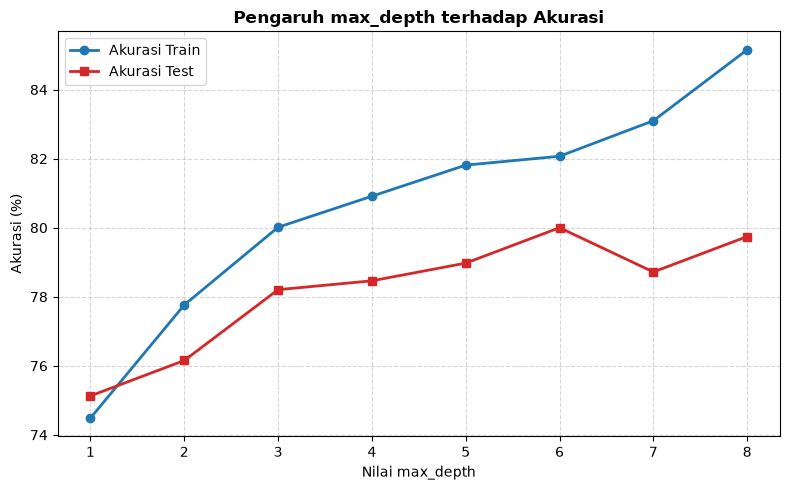

In [26]:
depths = range(1, 9)
acc_train = []
acc_test = []

for d in depths:
   
    rf = RandomForest(n_trees=20, max_depth=d, min_samples_split=5)
    rf.fit(X_train, y_train)
 
    pred_train = rf.predict(X_train)
    acc_tr = np.mean(pred_train == y_train) * 100
    acc_train.append(acc_tr)
    

    pred_test = rf.predict(X_test)
    acc_te = np.mean(pred_test == y_test) * 100
    acc_test.append(acc_te)


plt.figure(figsize=(8, 5))
plt.plot(depths, acc_train, marker='o', label='Akurasi Train', color='#1f77b4', linewidth=2)
plt.plot(depths, acc_test, marker='s', label='Akurasi Test', color='#d62728', linewidth=2)

plt.title('Pengaruh max_depth terhadap Akurasi', fontsize=12, fontweight='bold')
plt.xlabel('Nilai max_depth')
plt.ylabel('Akurasi (%)')
plt.xticks(depths)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

In [27]:
rf_terbaik = RandomForest(**best_p)
rf_terbaik.fit(X_train,y_train)

y_pred = rf_terbaik.predict(X_test)

In [28]:
# Akurasi model final (Random Forest terbaik)
akurasi_train = np.mean(rf_terbaik.predict(X_train) == y_train) * 100
akurasi_test  = np.mean(y_pred == y_test) * 100

print(f"Akurasi Data Latih : {akurasi_train:.2f}%")
print(f"Akurasi Data Uji   : {akurasi_test:.2f}%")

Akurasi Data Latih : 81.68%
Akurasi Data Uji   : 78.21%


In [29]:

y_true = y_test

TP = np.sum((y_true == 1) & (y_pred == 1))
TN = np.sum((y_true == 0) & (y_pred == 0))
FP = np.sum((y_true == 0) & (y_pred == 1))
FN = np.sum((y_true == 1) & (y_pred == 0))

presisi = (TP / (TP + FP)) * 100 if (TP + FP) > 0 else 0
recall = (TP / (TP + FN)) * 100 if (TP + FN) > 0 else 0
f1 = (2 * presisi * recall) / (presisi + recall) if (presisi + recall) > 0 else 0


print(f"Precision : {presisi:}")
print(f"Recall    : {recall:}")
print(f"F1-Score  : {f1:}")

Precision : 80.4093567251462
Recall    : 93.85665529010238
F1-Score  : 86.61417322834646


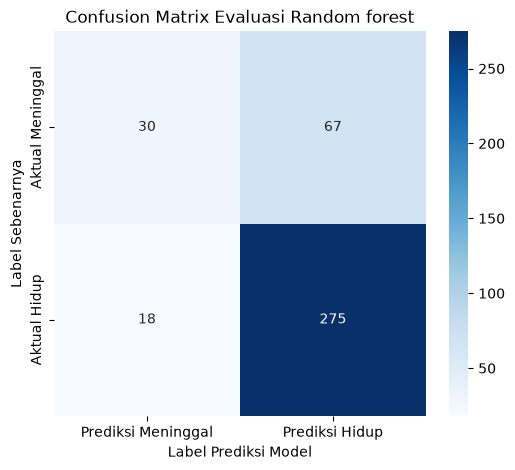

In [30]:
cm = np.array([[TN,FP] , [FN,TP]])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues',
    xticklabels=['Prediksi Meninggal', 'Prediksi Hidup'],
    yticklabels=['Aktual Meninggal', 'Aktual Hidup']
)
plt.title('Confusion Matrix Evaluasi Random forest', fontsize=12)
plt.ylabel('Label Sebenarnya')
plt.xlabel('Label Prediksi Model')
plt.show()

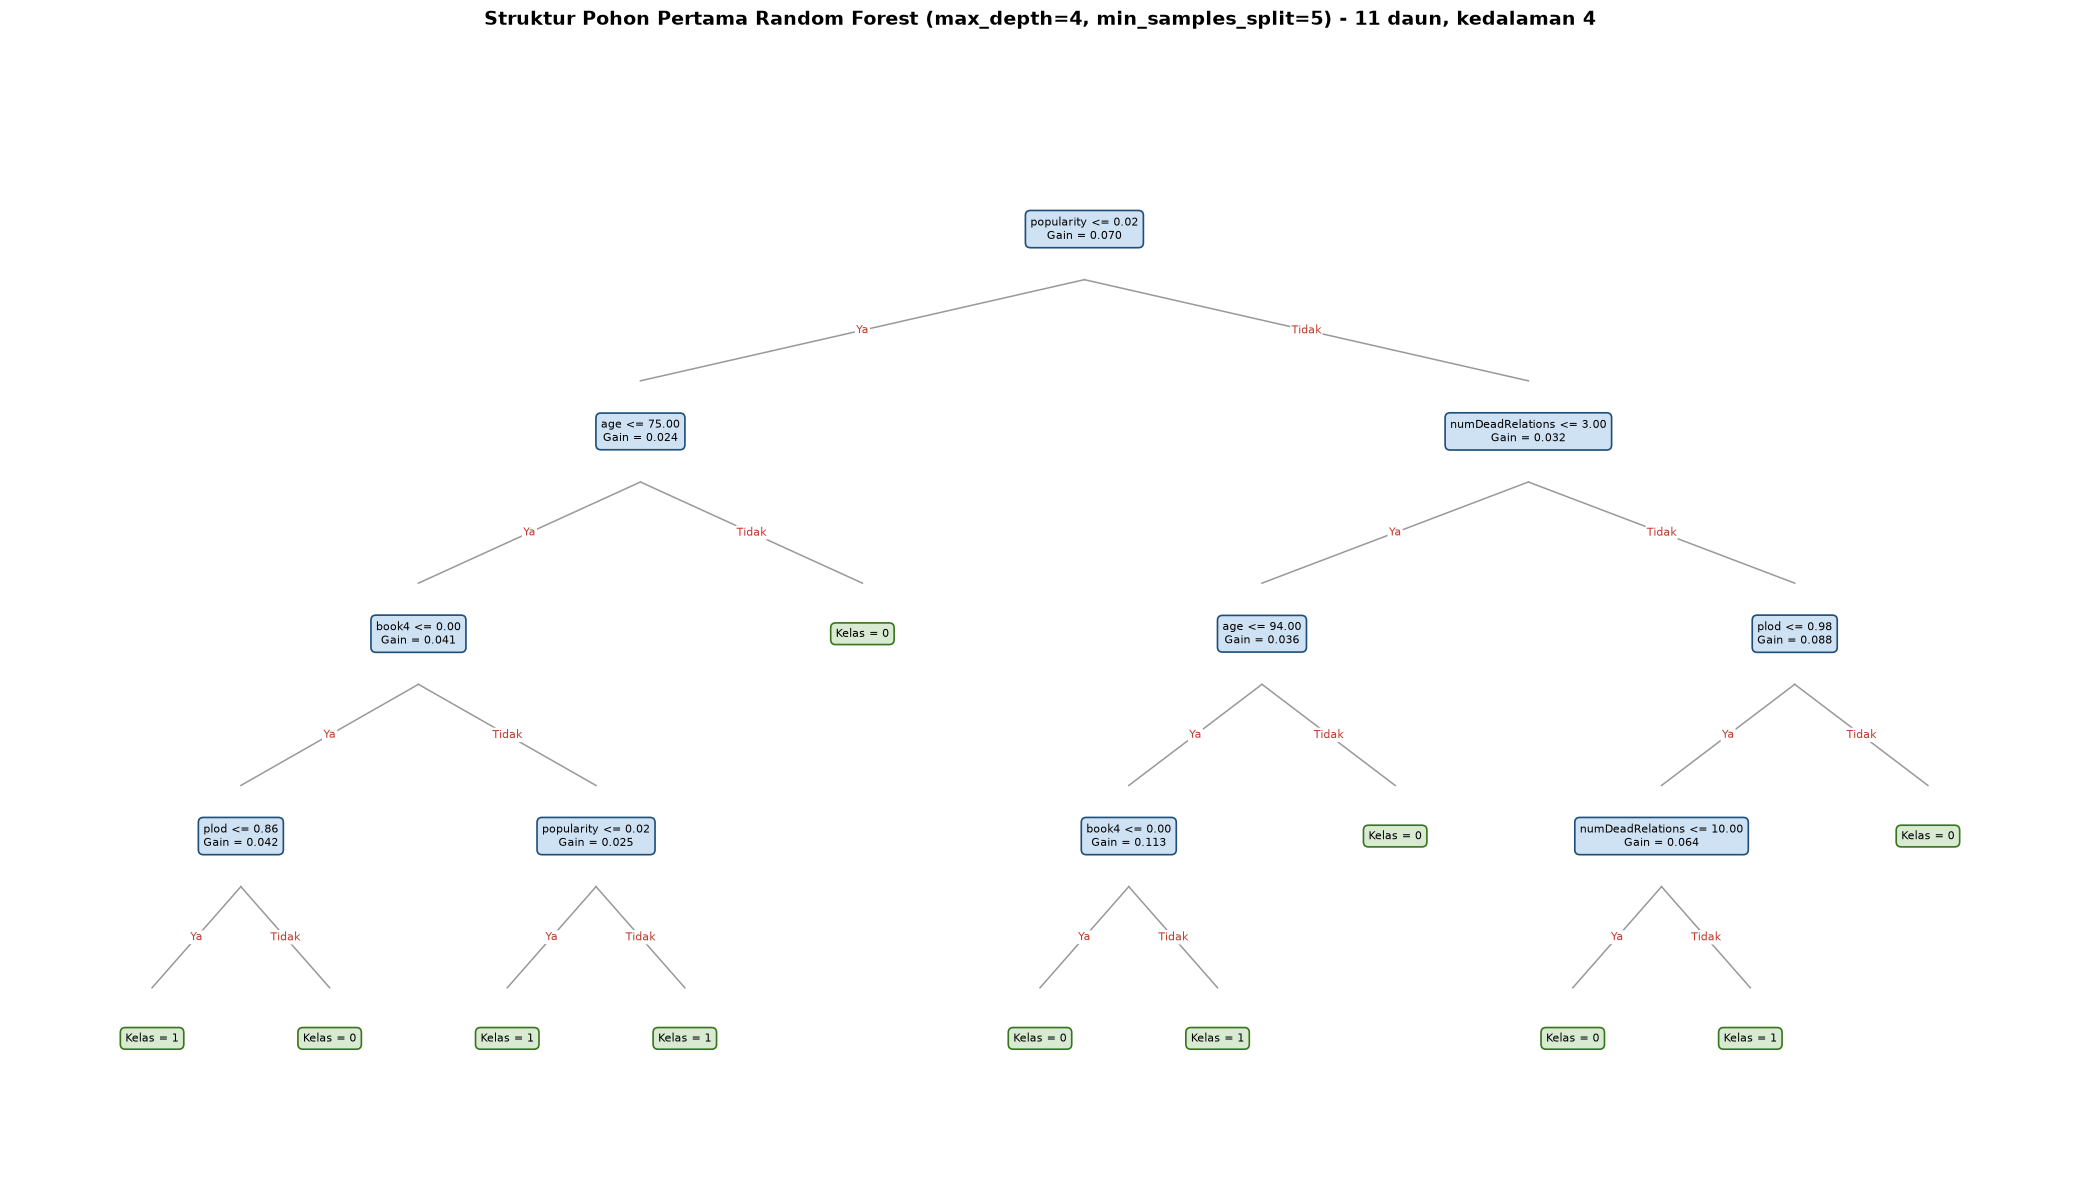

In [31]:
NAMA_FITUR = X.columns.tolist()

root = rf_terbaik.trees[0].tree

def kedalaman_pohon(node):
    if not isinstance(node, dict):
        return 0
    return 1 + max(kedalaman_pohon(node['left']), kedalaman_pohon(node['right']))


_daun = [0]

def atur_posisi(node, depth):
    if not isinstance(node, dict):
        x = float(_daun[0])
        _daun[0] += 1
        return {'x': x, 'depth': depth, 'daun': True, 'node': node}
    kiri = atur_posisi(node['left'], depth + 1)
    kanan = atur_posisi(node['right'], depth + 1)
    return {'x': (kiri['x'] + kanan['x']) / 2, 'depth': depth,
            'kiri': kiri, 'kanan': kanan, 'node': node}

posisi = atur_posisi(root, 0)
depth_max = kedalaman_pohon(root)
jumlah_daun = _daun[0]

fig, ax = plt.subplots(figsize=(max(14, jumlah_daun * 1.9), (depth_max + 1) * 2.4))
ax.axis("off")

def gambar_node(lay):
    node = lay['node']
    x, y = lay['x'], -lay['depth']

    if lay.get('daun'):
        teks = f"Kelas = {node}"
        warna, garis = "#d9ead3", "#38761d"
    else:
        teks = (f"{NAMA_FITUR[node['feat']]} <= {node['val']:,.2f}\n"
                f"Gain = {node['gain']:.3f}")
        warna, garis = "#cfe2f3", "#1f4e79"

    ax.text(x, y, teks, ha="center", va="center", fontsize=8, zorder=2,
            bbox=dict(boxstyle="round,pad=0.45", facecolor=warna,
                      edgecolor=garis, linewidth=1.2))

    if lay.get('daun'):
        return

    for anak, tanda in ((lay['kiri'], "Ya"), (lay['kanan'], "Tidak")):
        xa, ya = anak['x'], -anak['depth']
        ax.plot([x, xa], [y - 0.25, ya + 0.25], color="#999999", linewidth=1.1, zorder=1)
        ax.text((x + xa) / 2, (y + ya) / 2, tanda, ha="center", va="center",
                fontsize=8, color="#c0392b", zorder=3,
                bbox=dict(boxstyle="round,pad=0.12", facecolor="white", edgecolor="none"))
        gambar_node(anak)


gambar_node(posisi)

ax.set_xlim(-0.8, jumlah_daun - 0.2)
ax.set_ylim(-depth_max - 0.7, 0.9)
ax.set_title(
    f"Struktur Pohon Pertama Random Forest (max_depth={rf_terbaik.max_depth}, "
    f"min_samples_split={rf_terbaik.min_samples_split}) - {jumlah_daun} daun, kedalaman {depth_max}",
    fontsize=14, fontweight="bold", pad=16)

plt.tight_layout()
plt.show()



### **Feature Importance (Pengaruh Tiap Fitur)**

Menghitung seberapa besar kontribusi tiap fitur terhadap keputusan Random Forest, sebagai pengganti interpretasi visual pohon tunggal.

10 fitur paling berpengaruh:
            Fitur  Importance
             plod    0.365438
       popularity    0.182933
            book4    0.126133
              age    0.121539
            house    0.035002
            book5    0.024838
          culture    0.023460
 numDeadRelations    0.022563
boolDeadRelations    0.013221
            book1    0.011421


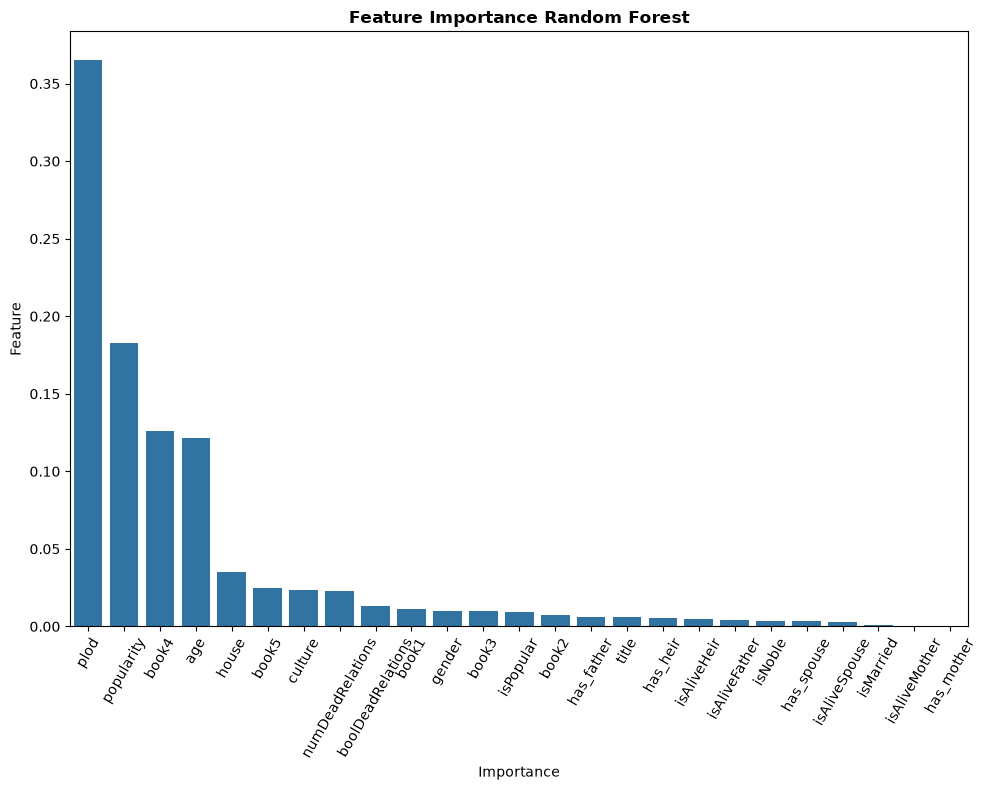

,Fitur,Importance
0,plod,0.365438
1,popularity,0.182933
2,book4,0.126133
3,age,0.121539
4,house,0.035002
5,book5,0.024838
6,culture,0.023460
7,numDeadRelations,0.022563
8,boolDeadRelations,0.013221
9,book1,0.011421


In [32]:
# Feature Importance dari Random Forest terbaik
importance = rf_terbaik.feature_importances()

df_importance = (
    pd.DataFrame({'Fitur': X.columns, 'Importance': importance})
    .sort_values(by='Importance', ascending=False)
    .reset_index(drop=True)
)

print("10 fitur paling berpengaruh:")
print(df_importance.head(10).to_string(index=False))

plt.figure(figsize=(10, 8))
sns.barplot(x='Fitur', y='Importance', data=df_importance, color='#1f77b4')
plt.title('Feature Importance Random Forest', fontsize=12, fontweight='bold')
plt.xlabel('Importance')
plt.xticks(rotation=60)
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

df_importance

# **6. Visualisasi Majority Voting Random Forest**

Instance ke-0
Kelas sebenarnya (y_true): 0
Jumlah pohon: 20
Vote tiap kelas: {np.int64(1): 18, np.int64(0): 2}
Kelas final (majority vote): 1


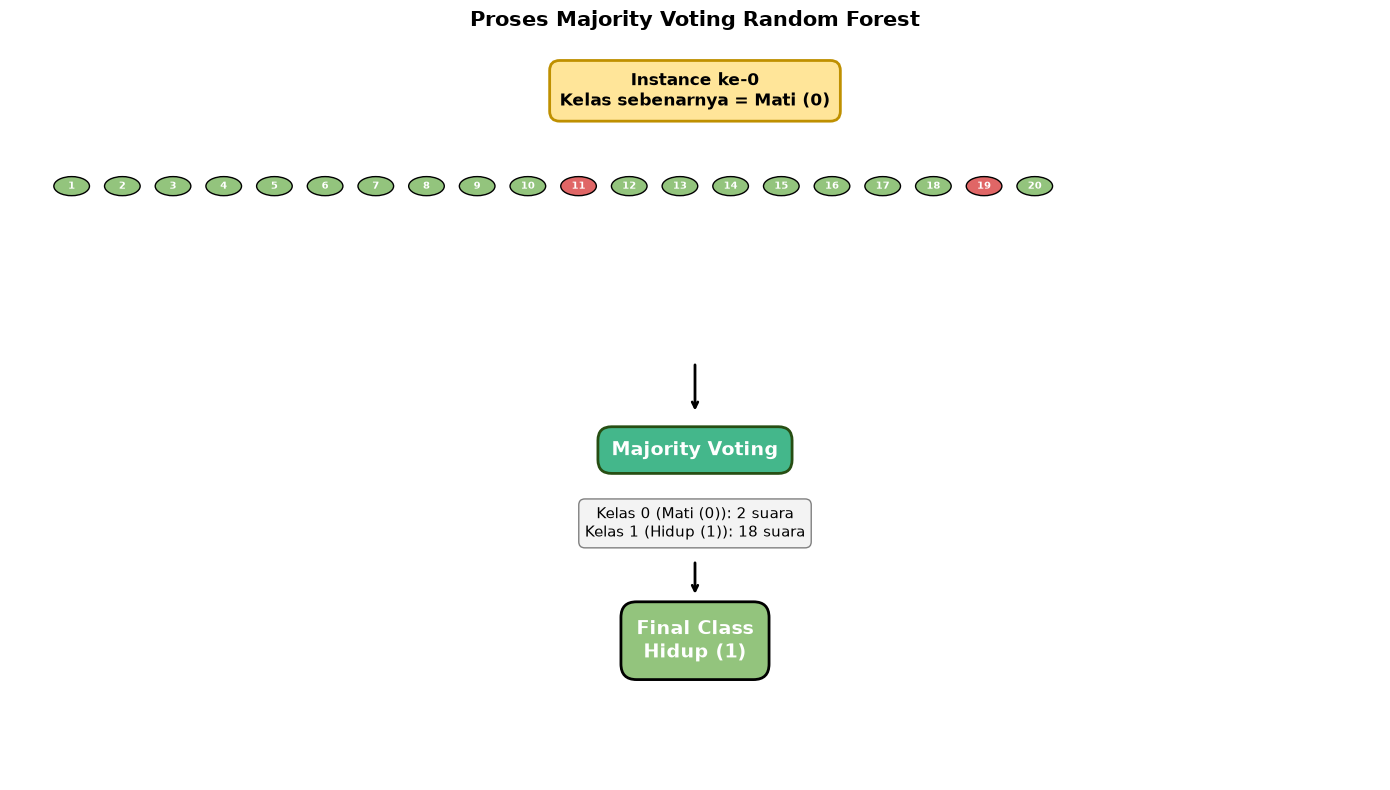

In [33]:
# Pilih satu instance dari data test (bisa ganti nilai idx)
idx = 0
instance = X_test[idx]
y_true = y_test[idx]

# 1. Prediksi dari setiap pohon di dalam Random Forest
preds_per_tree = np.array([tree.predict(instance.reshape(1, -1))[0] for tree in rf_terbaik.trees])

# 2. Majority Voting
vote_counts = Counter(preds_per_tree)
final_class = vote_counts.most_common(1)[0][0]

print(f"Instance ke-{idx}")
print(f"Kelas sebenarnya (y_true): {y_true}")
print(f"Jumlah pohon: {len(rf_terbaik.trees)}")
print(f"Vote tiap kelas: {dict(vote_counts)}")
print(f"Kelas final (majority vote): {final_class}")

# Warna: 0 = Mati (merah), 1 = Hidup (hijau)
color_map = {0: '#e06666', 1: '#93c47d'}
label_map = {0: 'Mati (0)', 1: 'Hidup (1)'}

fig, ax = plt.subplots(figsize=(14, 8))
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis('off')

# Kotak Instance
ax.text(5, 9.4, f"Instance ke-{idx}\nKelas sebenarnya = {label_map.get(y_true, y_true)}",
        ha='center', va='center', fontsize=12, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.6', facecolor='#ffe599', edgecolor='#bf9000', linewidth=2))

# Prediksi tiap pohon (lingkaran berwarna = hasil prediksi pohon ke-i)
tree_per_row = 25
for i, p in enumerate(preds_per_tree):
    r = i // tree_per_row
    c = i % tree_per_row
    x = 0.45 + c * 0.37
    y = 8.1 - r * 0.85
    ax.add_patch(plt.Circle((x, y), 0.13, color=color_map.get(p, '#cccccc'), ec='black', lw=1.0))
    ax.text(x, y, str(i+1), ha='center', va='center', fontsize=7, fontweight='bold', color='white')

# Panah ke Majority Voting
ax.annotate('', xy=(5, 5.0), xytext=(5, 5.7),
            arrowprops=dict(arrowstyle='->', lw=2, color='black'))

# Kotak Majority Voting
ax.text(5, 4.5, "Majority Voting",
        ha='center', va='center', fontsize=14, fontweight='bold', color='white',
        bbox=dict(boxstyle='round,pad=0.7', facecolor='#44b78b', edgecolor='#274e13', linewidth=2))

# Jumlah vote tiap kelas
vote_text = "\n".join([f"Kelas {k} ({label_map.get(k,'')}): {v} suara" for k, v in sorted(vote_counts.items())])
ax.text(5, 3.5, vote_text, ha='center', va='center', fontsize=11,
        bbox=dict(boxstyle='round,pad=0.4', facecolor='#f3f3f3', edgecolor='gray'))

# Panah ke Final Class
ax.annotate('', xy=(5, 2.5), xytext=(5, 3.0),
            arrowprops=dict(arrowstyle='->', lw=2, color='black'))

# Kotak Final Class
final_color = color_map.get(final_class, '#cccccc')
ax.text(5, 1.9, f"Final Class\n{label_map.get(final_class, final_class)}",
        ha='center', va='center', fontsize=14, fontweight='bold', color='white',
        bbox=dict(boxstyle='round,pad=0.8', facecolor=final_color, edgecolor='black', linewidth=2))

ax.set_title("Proses Majority Voting Random Forest", fontsize=15, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


# **7. GUI**

In [34]:
# ============================================================
# 2. KONFIGURASI ENCODING
# ============================================================
# Kolom kategorikal (title, culture, house) diubah menjadi angka
# dengan pd.factorize pada tahap preprocessing. Kode kategori =
# posisi kategori pada data latih, sehingga urutannya dihitung
# ulang dari data latih yang sama agar konsisten dengan X_train.

KOLOM_KATEGORIK = X.select_dtypes(include=['object', 'str']).columns.tolist()

X_train_enc, _, _, _ = split_data(X, df['isAlive'])

ENCODING = {}
for col in KOLOM_KATEGORIK:
    _, uniques = pd.factorize(X_train_enc[col].fillna('Unknown'))
    ENCODING[col] = {kategori: kode for kode, kategori in enumerate(uniques)}


# ============================================================
# 3. KONFIGURASI INPUT NUMERIK
# ============================================================

NUMERIK_DEFAULT = {
    col: round(float(df[col].median()), 4)
    for col in X.columns
    if col not in KOLOM_KATEGORIK
}

NUMERIK_LABEL = {
    "plod": "Plod (skor)",
    "gender": "Gender (1=Pria, 0=Wanita)",
    "book1": "Muncul Book 1 (0/1)",
    "book2": "Muncul Book 2 (0/1)",
    "book3": "Muncul Book 3 (0/1)",
    "book4": "Muncul Book 4 (0/1)",
    "book5": "Muncul Book 5 (0/1)",
    "isAliveMother": "Ibu Hidup (-1/0/1)",
    "isAliveFather": "Ayah Hidup (-1/0/1)",
    "isAliveHeir": "Ahli Waris Hidup (-1/0/1)",
    "isAliveSpouse": "Pasangan Hidup (-1/0/1)",
    "isMarried": "Menikah (0/1)",
    "isNoble": "Bangsawan (0/1)",
    "age": "Usia (tahun)",
    "numDeadRelations": "Kerabat Meninggal",
    "boolDeadRelations": "Punya Kerabat Mati (0/1)",
    "isPopular": "Populer (0/1)",
    "popularity": "Skor Popularitas",
    "has_mother": "Punya Ibu (0/1)",
    "has_father": "Punya Ayah (0/1)",
    "has_heir": "Punya Ahli Waris (0/1)",
    "has_spouse": "Punya Pasangan (0/1)",
}

# Fitur wajib harus sama persis dengan kolom X_train
FITUR_WAJIB = list(X.columns)

# Jumlah fitur teratas yang ditampilkan sebagai input di GUI
TOP_N_FITUR = 10


# ============================================================
# 4. CLASS APLIKASI
# ============================================================

class Aplikasi(tk.Tk):

    def __init__(self, model, data, fitur, akurasi, nama_model):

        super().__init__()

        # Dependency dari luar class
        self.model = model
        self.data = data
        self.fitur = fitur
        self.akurasi = akurasi
        self.nama_model = nama_model

        # Penyimpanan komponen GUI
        self.entries = {}
        self.combos = {}

        # Daftar kategori untuk tiap kolom kategorikal
        self.pilihan = {
            col: list(mapping.keys())
            for col, mapping in ENCODING.items()
        }

        # Validasi fitur model
        for col in FITUR_WAJIB:
            if col not in self.fitur:
                raise ValueError(
                    f"Fitur '{col}' tidak ditemukan dalam X_train."
                )

        # Feature importance otomatis dari model
        skor_importance = np.asarray(
            self.model.feature_importances(),
            dtype=float
        )

        self.importance = sorted(
            zip(self.fitur, skor_importance),
            key=lambda pasangan: pasangan[1],
            reverse=True
        )

        # Hanya fitur teratas yang tampil sebagai input GUI
        self.fitur_tampil = [
            nama for nama, _ in self.importance[:TOP_N_FITUR]
        ]

        # Pengaturan jendela
        self.title("Prediksi Kelangsungan Hidup Karakter")
        self.resizable(False, False)

        # Bangun tampilan
        self._bangun_form()

        # Sesuaikan ukuran jendela dengan jumlah field yang tampil
        self.update_idletasks()

        self.geometry(
            f"{max(820, self.winfo_reqwidth())}x{self.winfo_reqheight()}"
        )


    # ========================================================
    # 5. ENCODING INPUT
    # ========================================================

    def encode_input(self, data):

        hasil = {}

        # Encoding kategorikal (label encoding dari pd.factorize)
        for col, mapping in ENCODING.items():

            # Kolom kategorikal yang tidak tampil di GUI pakai kategori default
            kategori = data.get(col, self.pilihan[col][0])

            if kategori not in mapping:
                raise ValueError(
                    f"Kategori '{kategori}' pada {col} tidak valid."
                )

            hasil[col] = float(mapping[kategori])

        return hasil


    # ========================================================
    # 6. MENYUSUN DATA INPUT MENJADI ARRAY NUMPY
    # ========================================================

    def susun_baris(self, data):

        # Ambil fitur numerik
        hasil = {}

        for col in NUMERIK_DEFAULT:
            # Kolom numerik yang tidak tampil di GUI pakai nilai default (median)
            hasil[col] = float(data.get(col, NUMERIK_DEFAULT[col]))

        # Tambahkan hasil encoding
        hasil.update(self.encode_input(data))

        # Pastikan seluruh fitur tersedia
        fitur_hilang = [
            col for col in self.fitur
            if col not in hasil
        ]

        if fitur_hilang:
            raise ValueError(
                f"Fitur belum tersedia: {fitur_hilang}"
            )

        # Susun berdasarkan urutan X_train
        return np.array(
            [hasil[col] for col in self.fitur],
            dtype=float
        )


    # ========================================================
    # 7. MEMBANGUN GUI
    # ========================================================

    def _bangun_form(self):

        header = tk.Frame(
            self,
            bg="#1f4e79",
            height=70
        )

        header.pack(fill="x")

        tk.Label(
            header,
            text="Prediksi Kelangsungan Hidup Karakter",
            bg="#1f4e79",
            fg="white",
            font=("Segoe UI", 14, "bold")
        ).pack(pady=(12, 0))

        tk.Label(
            header,
            text=self.nama_model,
            bg="#1f4e79",
            fg="#cfe2f3",
            font=("Segoe UI", 10)
        ).pack(pady=(0, 12))


        form = ttk.Frame(self, padding=20)
        form.pack(fill="both", expand=True)

        form.columnconfigure(0, weight=1)
        form.columnconfigure(2, weight=1)

        # Input numerik (2 kolom agar ringkas)
        # Hanya fitur teratas yang ditampilkan, urut dari pengaruh terbesar
        numerik_tampil = {
            col: NUMERIK_LABEL[col]
            for col in self.fitur_tampil
            if col in NUMERIK_LABEL
        }

        for i, (col, label) in enumerate(numerik_tampil.items()):

            kolom = (i % 2) * 2
            baris = i // 2

            ttk.Label(
                form,
                text=label,
                font=("Segoe UI", 9)
            ).grid(
                row=baris,
                column=kolom,
                sticky="w",
                pady=4,
                padx=(0, 6)
            )

            entry = ttk.Entry(
                form,
                font=("Segoe UI", 9),
                width=14
            )

            entry.insert(
                0,
                str(NUMERIK_DEFAULT[col])
            )

            entry.grid(
                row=baris,
                column=kolom + 1,
                sticky="ew",
                pady=4,
                padx=(0, 14)
            )

            self.entries[col] = entry

        r = (len(numerik_tampil) + 1) // 2

        # Input kategorikal (hanya yang termasuk fitur teratas)
        for col, mapping in ENCODING.items():

            if col not in self.fitur_tampil:
                continue

            ttk.Label(
                form,
                text=col.replace("_", " ").capitalize(),
                font=("Segoe UI", 9)
            ).grid(
                row=r,
                column=0,
                sticky="w",
                pady=4,
                padx=(0, 6)
            )

            combo = ttk.Combobox(
                form,
                values=self.pilihan[col],
                state="readonly",
                font=("Segoe UI", 9)
            )

            combo.current(0)

            combo.grid(
                row=r,
                column=1,
                columnspan=3,
                sticky="ew",
                pady=4
            )

            self.combos[col] = combo

            r += 1


        # Tombol
        btns = ttk.Frame(form)

        btns.grid(
            row=r,
            column=0,
            columnspan=4,
            sticky="ew",
            pady=(16, 6)
        )

        btns.columnconfigure(
            (0, 1, 2),
            weight=1
        )

        ttk.Button(
            btns,
            text="Isi Otomatis",
            command=self.on_autofill
        ).grid(
            row=0,
            column=0,
            sticky="ew",
            padx=(0, 5),
            ipady=6
        )

        ttk.Button(
            btns,
            text="Prediksi",
            command=self.on_predict
        ).grid(
            row=0,
            column=1,
            sticky="ew",
            padx=5,
            ipady=6
        )

        ttk.Button(
            btns,
            text="Reset",
            command=self.on_reset
        ).grid(
            row=0,
            column=2,
            sticky="ew",
            padx=(5, 0),
            ipady=6
        )


        # Tombol contoh otomatis kelas 0 dan 1
        contoh = ttk.Frame(form)

        contoh.grid(
            row=r + 1,
            column=0,
            columnspan=4,
            sticky="ew",
            pady=(0, 6)
        )

        contoh.columnconfigure(
            (0, 1),
            weight=1
        )

        ttk.Button(
            contoh,
            text="Contoh Meninggal (0)",
            command=lambda: self.on_contoh(0)
        ).grid(
            row=0,
            column=0,
            sticky="ew",
            padx=(0, 5),
            ipady=6
        )

        ttk.Button(
            contoh,
            text="Contoh Hidup (1)",
            command=lambda: self.on_contoh(1)
        ).grid(
            row=0,
            column=1,
            sticky="ew",
            padx=(5, 0),
            ipady=6
        )


        # Hasil prediksi
        self.result_var = tk.StringVar(
            value="Isi data karakter lalu tekan Prediksi."
        )

        self.result_label = tk.Label(
            form,
            textvariable=self.result_var,
            font=("Segoe UI", 12, "bold"),
            bg="#f2f2f2",
            fg="#333333",
            wraplength=700,
            justify="center",
            pady=16
        )

        self.result_label.grid(
            row=r + 2,
            column=0,
            columnspan=4,
            sticky="ew",
            pady=(6, 0)
        )

        # Feature importance dihitung otomatis dari model
        self._bangun_importance(form, r + 3)


        # Informasi evaluasi model
        tk.Label(
            self,
            text=f"Model siap - Akurasi uji {self.akurasi:.2f}%",
            font=("Segoe UI", 9),
            fg="#666666"
        ).pack(
            side="bottom",
            pady=6
        )


    # ========================================================
    # 7B. FEATURE IMPORTANCE OTOMATIS
    # ========================================================

    def _bangun_importance(self, parent, baris):

        wadah = ttk.LabelFrame(
            parent,
            text=(
                "Feature Importance "
                f"(biru = {TOP_N_FITUR} fitur teratas, dipakai sebagai input GUI)"
            ),
            padding=8
        )

        wadah.grid(
            row=baris,
            column=0,
            columnspan=4,
            sticky="ew",
            pady=(10, 0)
        )

        # Pakai hasil importance yang sudah dihitung saat init
        data_importance = self.importance

        tabel = ttk.Treeview(
            wadah,
            columns=("fitur", "importance"),
            show="headings",
            height=6
        )

        tabel.heading("fitur", text="Fitur")
        tabel.heading("importance", text="Importance")

        tabel.column("fitur", anchor="w", width=220)
        tabel.column("importance", anchor="e", width=110)

        tabel.tag_configure("tampil", background="#e8f0fe")

        for fitur, nilai in data_importance:

            tabel.insert(
                "",
                tk.END,
                values=(fitur, f"{nilai:.4f}"),
                tags=("tampil",) if fitur in self.fitur_tampil else ()
            )

        scroll = ttk.Scrollbar(
            wadah,
            orient="vertical",
            command=tabel.yview
        )

        tabel.configure(yscrollcommand=scroll.set)

        tabel.pack(side="left", fill="both", expand=True)
        scroll.pack(side="right", fill="y")


    # ========================================================
    # 8. MENGAMBIL INPUT DARI GUI
    # ========================================================

    def ambil_input(self):

        data = {}

        # Ambil data numerik
        for col, entry in self.entries.items():

            teks = entry.get().strip().replace(",", ".")

            if not teks:
                raise ValueError(
                    f"{NUMERIK_LABEL[col]} tidak boleh kosong."
                )

            try:
                angka = float(teks)

            except ValueError:
                raise ValueError(
                    f"{NUMERIK_LABEL[col]} harus berupa angka."
                )

            if not np.isfinite(angka):
                raise ValueError(
                    f"{NUMERIK_LABEL[col]} harus berupa angka valid."
                )

            data[col] = angka


        # Ambil kategori dari Combobox
        for col, combo in self.combos.items():

            kategori = combo.get().strip()

            if not kategori:
                raise ValueError(
                    f"Silakan pilih kategori {col}."
                )

            data[col] = kategori

        return data


    # ========================================================
    # 9. AUTOFILL
    # ========================================================

    def on_autofill(self):

        try:

            baris = self.data.sample(n=1).iloc[0]

            # Isi numerik
            for col, entry in self.entries.items():

                nilai = baris[col]

                if pd.notna(nilai):

                    entry.delete(0, tk.END)

                    entry.insert(
                        0,
                        str(int(nilai))
                        if float(nilai).is_integer()
                        else str(nilai)
                    )


            # Isi kategori hasil label encoding
            for col in self.combos:

                nilai = baris[col]

                kategori = (
                    "Unknown"
                    if pd.isna(nilai)
                    else str(nilai).strip()
                )

                if kategori not in self.pilihan[col]:
                    kategori = "Unknown"

                self.combos[col].set(kategori)


            self.result_var.set(
                "Data contoh terisi otomatis. Tekan Prediksi untuk melihat hasil."
            )

            self.result_label.configure(
                bg="#f2f2f2",
                fg="#333333"
            )

        except Exception as exc:

            messagebox.showerror(
                "Autofill Gagal",
                str(exc)
            )


    # ========================================================
    # 9B. CONTOH OTOMATIS KELAS 0 DAN 1
    # ========================================================

    def on_contoh(self, kelas):

        try:

            for _, baris in self.data.iterrows():

                data = {}

                # Nilai numerik: pakai data baris, ganti dengan default bila kosong
                for col in NUMERIK_DEFAULT:

                    nilai = baris[col]

                    data[col] = (
                        float(nilai)
                        if pd.notna(nilai)
                        else float(NUMERIK_DEFAULT[col])
                    )

                # Nilai kategorikal: pakai hasil label encoding yang sama
                for col in ENCODING:

                    nilai = baris[col]

                    kategori = (
                        "Unknown"
                        if pd.isna(nilai)
                        else str(nilai).strip()
                    )

                    if kategori not in self.pilihan[col]:
                        kategori = "Unknown"

                    data[col] = kategori

                # Lewati baris yang prediksinya bukan kelas yang dicari
                x = self.susun_baris(data)

                if int(self.model.predict(x.reshape(1, -1))[0]) != kelas:
                    continue

                # Tampilkan contoh ke form
                for col, entry in self.entries.items():

                    nilai = data[col]

                    entry.delete(0, tk.END)

                    entry.insert(
                        0,
                        str(int(nilai))
                        if float(nilai).is_integer()
                        else str(nilai)
                    )

                for col, combo in self.combos.items():
                    combo.set(data[col])

                label = "HIDUP" if kelas == 1 else "MENINGGAL"

                self.result_var.set(
                    f"Contoh otomatis kelas {kelas}: {label} (kelas {kelas})"
                )

                self.result_label.configure(
                    bg="#d9ead3" if kelas == 1 else "#f4cccc",
                    fg="#1e6b34" if kelas == 1 else "#a61c00"
                )

                return

            raise ValueError(
                f"Tidak ada baris data yang diprediksi sebagai kelas {kelas}."
            )

        except ValueError as exc:

            messagebox.showwarning(
                "Contoh tidak ditemukan",
                str(exc)
            )

        except Exception as exc:

            messagebox.showerror(
                "Terjadi Kesalahan",
                str(exc)
            )


    # ========================================================
    # 10. PREDIKSI
    # ========================================================

    def on_predict(self):

        try:

            # Ambil input mentah
            data = self.ambil_input()

            # Encoding dan susun fitur
            x = self.susun_baris(data)

            # Prediksi Random Forest manual
            kelas = int(
                self.model.predict(x.reshape(1, -1))[0]
            )

            label = "HIDUP" if kelas == 1 else "MENINGGAL"

            self.result_var.set(
                f"Prediksi Kelangsungan Hidup:\n{label} (kelas {kelas})"
            )

            self.result_label.configure(
                bg="#d9ead3" if kelas == 1 else "#f4cccc",
                fg="#1e6b34" if kelas == 1 else "#a61c00"
            )

        except ValueError as exc:

            messagebox.showwarning(
                "Input tidak valid",
                str(exc)
            )

        except Exception as exc:

            messagebox.showerror(
                "Terjadi Kesalahan",
                str(exc)
            )


    # ========================================================
    # 11. RESET
    # ========================================================

    def on_reset(self):

        for col, entry in self.entries.items():

            entry.delete(0, tk.END)

            entry.insert(
                0,
                str(NUMERIK_DEFAULT[col])
            )


        for combo in self.combos.values():
            combo.current(0)


        self.result_var.set(
            "Isi data karakter lalu tekan Prediksi."
        )

        self.result_label.configure(
            bg="#f2f2f2",
            fg="#333333"
        )


# ============================================================
# 12. MENJALANKAN APLIKASI
# ============================================================

if __name__ == "__main__":

    # Akurasi model terbaik pada data uji
    akurasi_uji = float(
        np.mean(rf_terbaik.predict(X_test) == y_test) * 100
    )

    app = Aplikasi(
        model=rf_terbaik,
        data=df,
        fitur=X.columns.tolist(),
        akurasi=akurasi_uji,
        nama_model="Random Forest"
    )

    app.mainloop()


## **8.0 Conclution**

### 8.1 Kesimpulan Dataset & Tahap Pre Processing

* **Missing Values**: Melakukan penanganan missing values mengisi kolom angka dengan median dan untuk kategorikal di isi dengan unknown
* **Encoding Data**: Melakukan encoding pada kolom kategorikal menjadi numerik
* **Feature engineerin**: Melakukan perubahan fitur untuk nama ibu ayah pasangan dan keturunan menjadi punya atau tidak untuk menghindari banyak data yang memiliki nama ayah yang sama

### 8.2 Kesimpulan Algoritma

* **Model yang Digunakan**: **Random Forest Classifier** yang dibangun dari scratch menggunakan Ensemble Bagging (Bootstrap Aggregating) dan Random Subspace Feature berbasis voting mayoritas..
* **Kelebihan**:
  1. Jauh lebih stabil dan tahan terhadap overfitting dibanding pohon tunggal berkat penggabungan banyak pohon (ensemble).
* **Kekurangan**:
  1. sulit diinterpretasikan secara visual karena menggabungkan puluhan struktur pohon sekaligus.
  2. Komputasi lambat: waktu latih dan prediksi meningkat drastis seiring bertambahnya jumlah pohon (n_trees)
  3. Membutuhkan memori besar untuk menyimpan seluruh objek pohon di dalam RAM.
  4. Cenderung bias ke kelas mayoritas jika menghadapi data target yang tidak seimbang (imbalanced data).
* **Solusi**:
  1. Menganalisis pengaruh variabel secara global menggunakan Feature Importance sebagai pengganti visualisasi pohon tunggal.
  2. Membatasi jumlah pohon (n_trees) secukupnya dan memangkas kedalaman (max_depth) agar komputasi tetap efisien
  3. Menerapkan Hyperparameter Tuning (Random Search) untuk menemukan kombinasi parameter paling optimal.
  4. Menerapkan penyesuaian bobot sampel (class weight) atau evaluasi metrik berbasis F1-Score/Confusion Matrix untuk menangani ketimpangan kelas.

### 8.3 Hasil Analisis Evaluasi

1. **Akurasi Model:**
   Akurasi model Random Forest mencapai 79.23%, menunjukkan performa yang sangat baik dan konsisten dalam memprediksi kelangsungan hidup karakter pada novel Game of Thrones.


2. **Precision:**
   Nilai Precision sebesar 80.06%, membuktikan bahwa 80.06% karakter yang diprediksi akan bertahan hidup (survive) memang terbukti benar-benar masih hidup.

3. **Recall:**
  Nilai Recall sebesar 95.90%, membuktikan model berhasil mendeteksi hampir seluruh karakter yang benar-benar hidup dengan sangat sedikit kasus yang terlewat.
  
3. **F1-Score:**
  Nilai F1-Score sebesar 87.27%, membuktikan adanya keseimbangan yang sangat solid dan tinggi antara Precision dan Recall.